# BrewScope — Stage 6: Group-Aware Stratified Data Splitting

Notebook ini membuat satu pembagian train/validation/test yang konsisten untuk Task A dan Task B. Split dilakukan pada `duplicate_group_id`, sehingga review identik tidak dapat bocor ke split berbeda. Distribusi enam label aspek dan kombinasi aspek-sentimen diseimbangkan dengan greedy multi-start stratification yang deterministik.

Notebook ini tidak melakukan TF-IDF, resampling, feature selection, atau training model. Seluruh proses tersebut harus dilakukan setelah split dan hanya menggunakan training set.

## 0. Persiapan environment

Jalankan dari environment proyek setelah notebook preprocessing selesai:

    python -m pip install -e ".[modeling]"

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300})

RANDOM_STATE = 42
N_STARTS = 50
SPLIT_RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}
SPLIT_NAMES = list(SPLIT_RATIOS)
ASPECTS = [
    "product_quality",
    "service",
    "price_value",
    "ambience",
    "facilities",
    "cleanliness",
]
SENTIMENTS = ["negative", "neutral", "positive"]
ASPECT_LABEL_COLUMNS = [f"aspect_{aspect}" for aspect in ASPECTS]

if not np.isclose(sum(SPLIT_RATIOS.values()), 1.0):
    raise ValueError("Proporsi split harus berjumlah 1.0.")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Root proyek tidak ditemukan.")

MODELING_DIR = PROJECT_ROOT / "data" / "processed" / "modeling"
TASK_A_INPUT = MODELING_DIR / "aspect_detection_dataset.csv"
TASK_B_INPUT = MODELING_DIR / "aspect_sentiment_dataset.csv"
SPLIT_DIR = MODELING_DIR / "splits"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "splitting"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "splitting"

print(f"Task A input: {TASK_A_INPUT.relative_to(PROJECT_ROOT)}")
print(f"Task B input: {TASK_B_INPUT.relative_to(PROJECT_ROOT)}")

Task A input: data\processed\modeling\aspect_detection_dataset.csv
Task B input: data\processed\modeling\aspect_sentiment_dataset.csv


## 1. Memuat dan memvalidasi dataset model-ready

In [2]:
task_a = pd.read_csv(TASK_A_INPUT, encoding="utf-8-sig", keep_default_na=False)
task_b = pd.read_csv(TASK_B_INPUT, encoding="utf-8-sig", keep_default_na=False)

required_task_a = {"review_id", "duplicate_group_id", *ASPECT_LABEL_COLUMNS}
required_task_b = {
    "annotation_id",
    "review_id",
    "duplicate_group_id",
    "aspect_category",
    "sentiment",
}
missing_a = sorted(required_task_a - set(task_a.columns))
missing_b = sorted(required_task_b - set(task_b.columns))
if missing_a or missing_b:
    raise ValueError(f"Kolom input kurang: Task A={missing_a}, Task B={missing_b}")

if task_a["review_id"].duplicated().any():
    raise ValueError("Task A harus memiliki satu baris per review_id.")
if task_b["annotation_id"].duplicated().any():
    raise ValueError("annotation_id Task B harus unik.")
if not task_a[ASPECT_LABEL_COLUMNS].isin([0, 1]).all().all():
    raise ValueError("Target Task A harus biner.")
if not task_b["sentiment"].isin(SENTIMENTS).all():
    raise ValueError("Task B memiliki label sentimen di luar kontrak.")

review_groups = pd.concat(
    [
        task_a[["review_id", "duplicate_group_id"]],
        task_b[["review_id", "duplicate_group_id"]],
    ],
    ignore_index=True,
).drop_duplicates()
if review_groups["review_id"].duplicated().any():
    raise ValueError("Satu review_id memiliki duplicate_group_id berbeda.")

print(f"Task A rows : {len(task_a):,}")
print(f"Task B rows : {len(task_b):,}")
print(f"Review union: {len(review_groups):,}")
print(f"Groups      : {review_groups['duplicate_group_id'].nunique():,}")

Task A rows : 3,424
Task B rows : 5,598
Review union: 3,424
Groups      : 3,200


## 2. Membentuk matriks stratifikasi tingkat review dan group

Matriks mencakup enam target positif Task A, indikator eligibility Task A, serta 18 kombinasi aspek-sentimen Task B. Nilai kemudian dijumlahkan pada tingkat duplicate group agar satu group selalu diperlakukan sebagai unit yang tidak dapat dipisah.

In [3]:
task_a_features = task_a[["review_id", *ASPECT_LABEL_COLUMNS]].copy()
task_a_features["task_a_eligible"] = 1

sentiment_features = pd.crosstab(
    task_b["review_id"],
    [task_b["aspect_category"], task_b["sentiment"]],
)
sentiment_features.columns = [
    f"sentiment_{aspect}_{sentiment}"
    for aspect, sentiment in sentiment_features.columns
]
sentiment_features = sentiment_features.gt(0).astype("int8").reset_index()

review_frame = (
    review_groups.merge(task_a_features, on="review_id", how="left")
    .merge(sentiment_features, on="review_id", how="left")
)
STRATIFY_COLUMNS = [
    *ASPECT_LABEL_COLUMNS,
    "task_a_eligible",
    *[
        f"sentiment_{aspect}_{sentiment}"
        for aspect in ASPECTS
        for sentiment in SENTIMENTS
    ],
]
for column in STRATIFY_COLUMNS:
    if column not in review_frame:
        review_frame[column] = 0
review_frame[STRATIFY_COLUMNS] = (
    review_frame[STRATIFY_COLUMNS].fillna(0).astype("int16")
)

group_features = review_frame.groupby("duplicate_group_id").agg(
    review_count=("review_id", "size"),
    **{column: (column, "sum") for column in STRATIFY_COLUMNS},
).reset_index()

display(group_features.head())

,duplicate_group_id,review_count,aspect_product_quality,aspect_service,aspect_price_value,aspect_ambience,aspect_facilities,aspect_cleanliness,task_a_eligible,sentiment_product_quality_negative,sentiment_product_quality_neutral,sentiment_product_quality_positive,sentiment_service_negative,sentiment_service_neutral,sentiment_service_positive,sentiment_price_value_negative,sentiment_price_value_neutral,sentiment_price_value_positive,sentiment_ambience_negative,sentiment_ambience_neutral,sentiment_ambience_positive,sentiment_facilities_negative,sentiment_facilities_neutral,sentiment_facilities_positive,sentiment_cleanliness_negative,sentiment_cleanliness_neutral,sentiment_cleanliness_positive
0,TXT_000FA3593442E4BB,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,TXT_001AA8390A437CBC,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,TXT_001E5380BD236B0E,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,TXT_0031CDBF756E9316,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,TXT_00403C940E5A3263,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


## 3. Greedy multi-start group stratification

Algoritma memprioritaskan group yang membawa label langka, lalu memilih split yang paling mengurangi selisih terhadap target ukuran dan target distribusi label. Beberapa urutan deterministik dicoba dan solusi dengan objective terkecil dipilih.

In [4]:
def split_objective(
    size_counts: np.ndarray,
    label_counts: np.ndarray,
    target_sizes: np.ndarray,
    target_labels: np.ndarray,
    total_labels: np.ndarray,
) -> float:
    size_error = np.mean(
        ((size_counts - target_sizes) / np.maximum(target_sizes, 1.0)) ** 2
    )
    label_error = np.mean(
        ((label_counts - target_labels) / np.maximum(target_labels, 1.0)) ** 2
    )
    eligible_for_coverage = total_labels >= len(SPLIT_NAMES)
    missing = (label_counts[:, eligible_for_coverage] == 0).mean()
    overflow = np.maximum(size_counts - target_sizes, 0.0)
    overflow_error = np.mean(
        (overflow / np.maximum(target_sizes, 1.0)) ** 2
    )
    return float(0.30 * size_error + 0.65 * label_error + 0.05 * missing + 2.0 * overflow_error)


def greedy_group_stratification(
    groups: pd.DataFrame, *, random_state: int, n_starts: int
) -> tuple[pd.Series, float]:
    ratios = np.array([SPLIT_RATIOS[name] for name in SPLIT_NAMES])
    sizes = groups["review_count"].to_numpy(dtype=float)
    labels = groups[STRATIFY_COLUMNS].to_numpy(dtype=float)
    total_labels = labels.sum(axis=0)
    target_sizes = ratios * sizes.sum()
    target_labels = ratios[:, None] * total_labels[None, :]
    rarity_weights = np.divide(
        1.0, total_labels, out=np.zeros_like(total_labels), where=total_labels > 0
    )
    rarity = (labels > 0).astype(float) @ rarity_weights

    best_assignment: np.ndarray | None = None
    best_score = float("inf")
    master_rng = np.random.default_rng(random_state)

    for _ in range(n_starts):
        rng = np.random.default_rng(master_rng.integers(0, 2**32 - 1))
        jitter = rng.random(len(groups))
        order = np.lexsort((jitter, -sizes, -rarity))
        assignment = np.full(len(groups), -1, dtype=int)
        size_counts = np.zeros(len(SPLIT_NAMES), dtype=float)
        label_counts = np.zeros((len(SPLIT_NAMES), len(STRATIFY_COLUMNS)))

        for group_index in order:
            candidate_scores: list[float] = []
            for split_index in range(len(SPLIT_NAMES)):
                proposed_sizes = size_counts.copy()
                proposed_labels = label_counts.copy()
                proposed_sizes[split_index] += sizes[group_index]
                proposed_labels[split_index] += labels[group_index]
                candidate_scores.append(
                    split_objective(
                        proposed_sizes,
                        proposed_labels,
                        target_sizes,
                        target_labels,
                        total_labels,
                    )
                )
            best_candidates = np.flatnonzero(
                np.isclose(candidate_scores, min(candidate_scores))
            )
            chosen = int(rng.choice(best_candidates))
            assignment[group_index] = chosen
            size_counts[chosen] += sizes[group_index]
            label_counts[chosen] += labels[group_index]

        score = split_objective(
            size_counts, label_counts, target_sizes, target_labels, total_labels
        )
        if score < best_score:
            best_score = score
            best_assignment = assignment.copy()

    if best_assignment is None or (best_assignment < 0).any():
        raise RuntimeError("Gagal membuat assignment split.")

    result = pd.Series(
        [SPLIT_NAMES[index] for index in best_assignment],
        index=groups["duplicate_group_id"],
        name="split",
    )
    return result, best_score

## 4. Membuat assignment dan menerapkannya ke kedua task

In [5]:
group_split, objective_score = greedy_group_stratification(
    group_features, random_state=RANDOM_STATE, n_starts=N_STARTS
)
split_assignments = review_frame[["review_id", "duplicate_group_id"]].copy()
split_assignments["split"] = split_assignments["duplicate_group_id"].map(
    group_split
)
split_assignments["split"] = pd.Categorical(
    split_assignments["split"], categories=SPLIT_NAMES, ordered=True
)

task_a_split = task_a.merge(
    split_assignments[["review_id", "split"]],
    on="review_id",
    how="left",
    validate="one_to_one",
)
task_b_split = task_b.merge(
    split_assignments[["review_id", "split"]],
    on="review_id",
    how="left",
    validate="many_to_one",
)
print(f"Best objective: {objective_score:.6f}")

Best objective: 0.056408


## 5. Validasi leakage dan cakupan kelas

In [6]:
if split_assignments["split"].isna().any():
    raise ValueError("Masih ada review tanpa split.")
if split_assignments["review_id"].duplicated().any():
    raise ValueError("split_assignments memiliki review_id duplikat.")
if split_assignments.groupby("duplicate_group_id")["split"].nunique().gt(1).any():
    raise ValueError("Duplicate group bocor ke lebih dari satu split.")
if len(task_a_split) != len(task_a) or len(task_b_split) != len(task_b):
    raise ValueError("Jumlah baris berubah setelah assignment split.")

task_a_positive_coverage = (
    task_a_split.groupby("split", observed=False)[ASPECT_LABEL_COLUMNS]
    .sum()
    .reindex(SPLIT_NAMES)
)
if task_a_positive_coverage.eq(0).any().any():
    raise ValueError("Ada label positif Task A yang tidak muncul pada suatu split.")

coverage_index = pd.MultiIndex.from_product(
    [SPLIT_NAMES, ASPECTS, SENTIMENTS],
    names=["split", "aspect_category", "sentiment"],
)
task_b_class_coverage = (
    task_b_split.groupby(
        ["split", "aspect_category", "sentiment"], observed=False
    )
    .size()
    .reindex(coverage_index, fill_value=0)
    .rename("count")
    .reset_index()
)
missing_classes = task_b_class_coverage.loc[
    task_b_class_coverage["count"].eq(0)
]
if not missing_classes.empty:
    display(missing_classes)
    raise ValueError("Ada kelas aspek-sentimen yang tidak terwakili pada suatu split.")

split_summary = pd.DataFrame(
    {
        "reviews": split_assignments["split"].value_counts(),
        "groups": (
            split_assignments.drop_duplicates("duplicate_group_id")["split"]
            .value_counts()
        ),
        "task_a_rows": task_a_split["split"].value_counts(),
        "task_b_rows": task_b_split["split"].value_counts(),
    }
).reindex(SPLIT_NAMES)
split_summary["review_percentage"] = (
    100 * split_summary["reviews"] / split_summary["reviews"].sum()
)
display(split_summary)
display(task_a_positive_coverage)
display(task_b_class_coverage)

,reviews,groups,task_a_rows,task_b_rows,review_percentage
split,,,,,
train,2396,2332,2396,3313,69.976636
validation,514,430,514,1143,15.011682
test,514,438,514,1142,15.011682


,aspect_product_quality,aspect_service,aspect_price_value,aspect_ambience,aspect_facilities,aspect_cleanliness
split,,,,,,
train,975,545,273,1284,201,114
validation,363,211,103,408,73,36
test,363,210,104,407,74,35


,split,aspect_category,sentiment,count
0,train,product_quality,negative,20
1,train,product_quality,neutral,241
2,train,product_quality,positive,689
3,train,service,negative,77
4,train,service,neutral,104
5,train,service,positive,352
6,train,price_value,negative,18
7,train,price_value,neutral,58
8,train,price_value,positive,192
9,train,ambience,negative,22


## 6. Diagnostik paper-ready

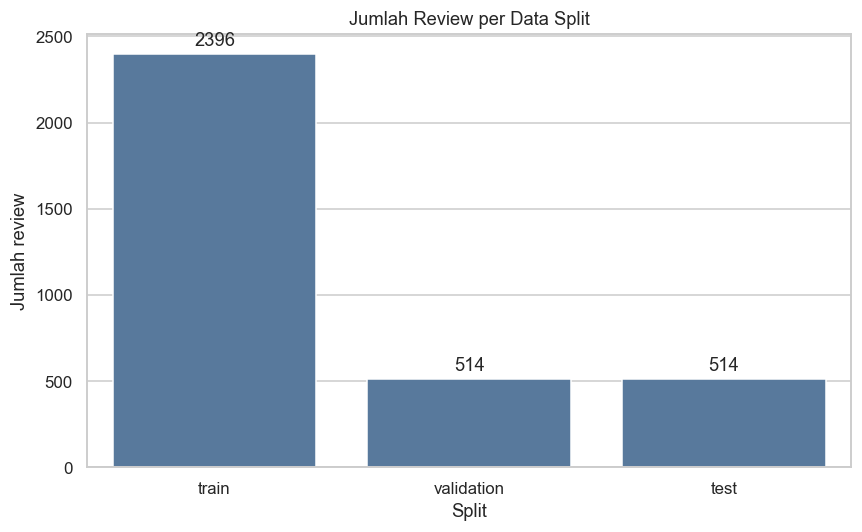

In [7]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

plot_data = split_summary.reset_index(names="split")
plt.figure(figsize=(8, 5))
axis = sns.barplot(data=plot_data, x="split", y="reviews", color="#4C78A8")
for container in axis.containers:
    axis.bar_label(container, padding=3)
plt.title("Jumlah Review per Data Split")
plt.xlabel("Split")
plt.ylabel("Jumlah review")
plt.tight_layout()
split_figure = FIGURE_DIR / "01_review_distribution_by_split.png"
plt.savefig(split_figure, dpi=300, bbox_inches="tight")
plt.show()

split_summary.to_csv(
    TABLE_DIR / "split_summary.csv", encoding="utf-8-sig"
)
task_a_positive_coverage.to_csv(
    TABLE_DIR / "task_a_positive_coverage.csv", encoding="utf-8-sig"
)
task_b_class_coverage.to_csv(
    TABLE_DIR / "task_b_class_coverage.csv",
    index=False,
    encoding="utf-8-sig",
)

## 7. Ekspor assignment, dataset bersplit, dan manifest

In [8]:
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
assignment_output = SPLIT_DIR / "split_assignments.csv"
task_a_output = SPLIT_DIR / "aspect_detection_with_split.csv"
task_b_output = SPLIT_DIR / "aspect_sentiment_with_split.csv"
manifest_output = SPLIT_DIR / "split_manifest.json"

split_assignments.sort_values(["split", "review_id"]).to_csv(
    assignment_output, index=False, encoding="utf-8-sig"
)
task_a_split.to_csv(task_a_output, index=False, encoding="utf-8-sig")
task_b_split.to_csv(task_b_output, index=False, encoding="utf-8-sig")

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

artifact_paths = [assignment_output, task_a_output, task_b_output]
manifest = {
    "stage": "group_aware_stratified_splitting",
    "inputs": {
        str(TASK_A_INPUT.relative_to(PROJECT_ROOT)): sha256_file(TASK_A_INPUT),
        str(TASK_B_INPUT.relative_to(PROJECT_ROOT)): sha256_file(TASK_B_INPUT),
    },
    "configuration": {
        "random_state": RANDOM_STATE,
        "n_starts": N_STARTS,
        "split_ratios": SPLIT_RATIOS,
        "group_column": "duplicate_group_id",
        "stratify_columns": STRATIFY_COLUMNS,
        "objective_score": objective_score,
    },
    "validation": {
        "group_leakage": False,
        "all_task_a_positive_labels_represented": True,
        "all_task_b_aspect_sentiment_classes_represented": True,
    },
    "counts": {
        "reviews": int(len(split_assignments)),
        "groups": int(split_assignments["duplicate_group_id"].nunique()),
        "task_a_rows": int(len(task_a_split)),
        "task_b_rows": int(len(task_b_split)),
        "reviews_by_split": {
            str(key): int(value)
            for key, value in split_summary["reviews"].items()
        },
    },
    "outputs": {},
    "notes": [
        "All duplicate groups remain in exactly one split.",
        "The same review split is reused for Task A and Task B.",
        "TF-IDF, resampling, and model fitting must use training rows only.",
    ],
}
for path in artifact_paths:
    manifest["outputs"][str(path.relative_to(PROJECT_ROOT))] = {
        "sha256": sha256_file(path),
        "bytes": path.stat().st_size,
    }
manifest_output.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("Splitting selesai. Output:")
for path in [*artifact_paths, manifest_output]:
    print(f"- {path.relative_to(PROJECT_ROOT)}")

Splitting selesai. Output:
- data\processed\modeling\splits\split_assignments.csv
- data\processed\modeling\splits\aspect_detection_with_split.csv
- data\processed\modeling\splits\aspect_sentiment_with_split.csv
- data\processed\modeling\splits\split_manifest.json


## 8. Kontrak tahap modeling

1. Gunakan kolom `split` yang sudah dibuat; jangan membuat split baru per algoritma.
2. Fit TF-IDF/CountVectorizer hanya pada baris train.
3. Terapkan class weighting atau resampling hanya pada train.
4. Task B utama menggunakan classifier terpisah per `aspect_category`; model gabungan menjadi pembanding.
5. Laporkan macro-F1, recall negatif, support, dan hasil per aspek selain accuracy.